In [27]:
# hence my accuracy on train datset is 84 and on test dataset it is 83 so no overfitting
# but for enhancing the performance more add features:
### batchNorm
### Dropout

### if there is a much gap in the train and test dataset (overfitting):
- adding more data
- reduce complexity of nn architecture
- Regularization
- Data Augmentation(in CNN)
- use another optimizer
- BatchNorm
- Dropout
- Early stop(when in epoch accuracy is not improving so stop at middle of epoch)

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [31]:
torch.manual_seed(42)

In [32]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{device} is available")

cuda is available


In [33]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "fashion-mnist_train.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "zalando-research/fashionmnist",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:")
print(df.head())

Using Colab cache for faster access to the 'fashionmnist' dataset.
First 5 records:
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0         0         1   
4       0  ...         0         0         0         0         0     

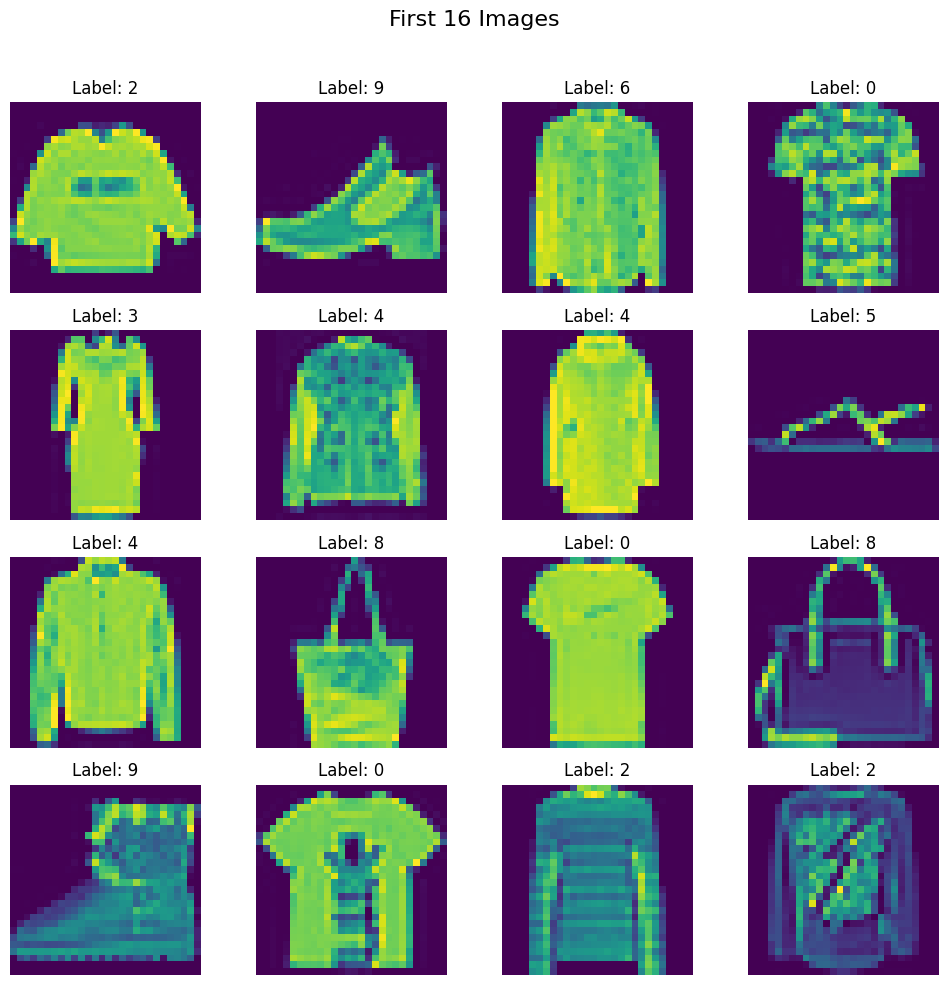

In [34]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()


In [35]:
# train Test split
x=df.iloc[:,1:].values
y=df.iloc[:,0].values

In [36]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [37]:
x_train=x_train/255.0
x_test=x_test/255.0

In [38]:
from torch.utils.data import Dataset,DataLoader

In [39]:
class MyDataset(Dataset):
  def __init__(self,features,labels):
    self.features=torch.tensor(features,dtype=torch.float32)
    self.labels=torch.tensor(labels,dtype=torch.long)
  def __len__(self):
    return self.features.shape[0]
  def __getitem__(self,idx):
    return self.features[idx],self.labels[idx]

train_dataset=MyDataset(x_train,y_train)

In [40]:
test_dataset=MyDataset(x_test,y_test)

In [41]:
train_loader=DataLoader(train_dataset,batch_size=64,shuffle=True,pin_memory=True)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=True,pin_memory=True)

### apply Dropout layer
- on hidden layers
- applied after ReLu(any activation function)
- during Evaluation it not used

### apply BatchNorm layer
- on hidden layers
- applied before  ReLu and after Linear layer
- includes learnable parameters
- improves training stability

1.   List item
2.   List item




- 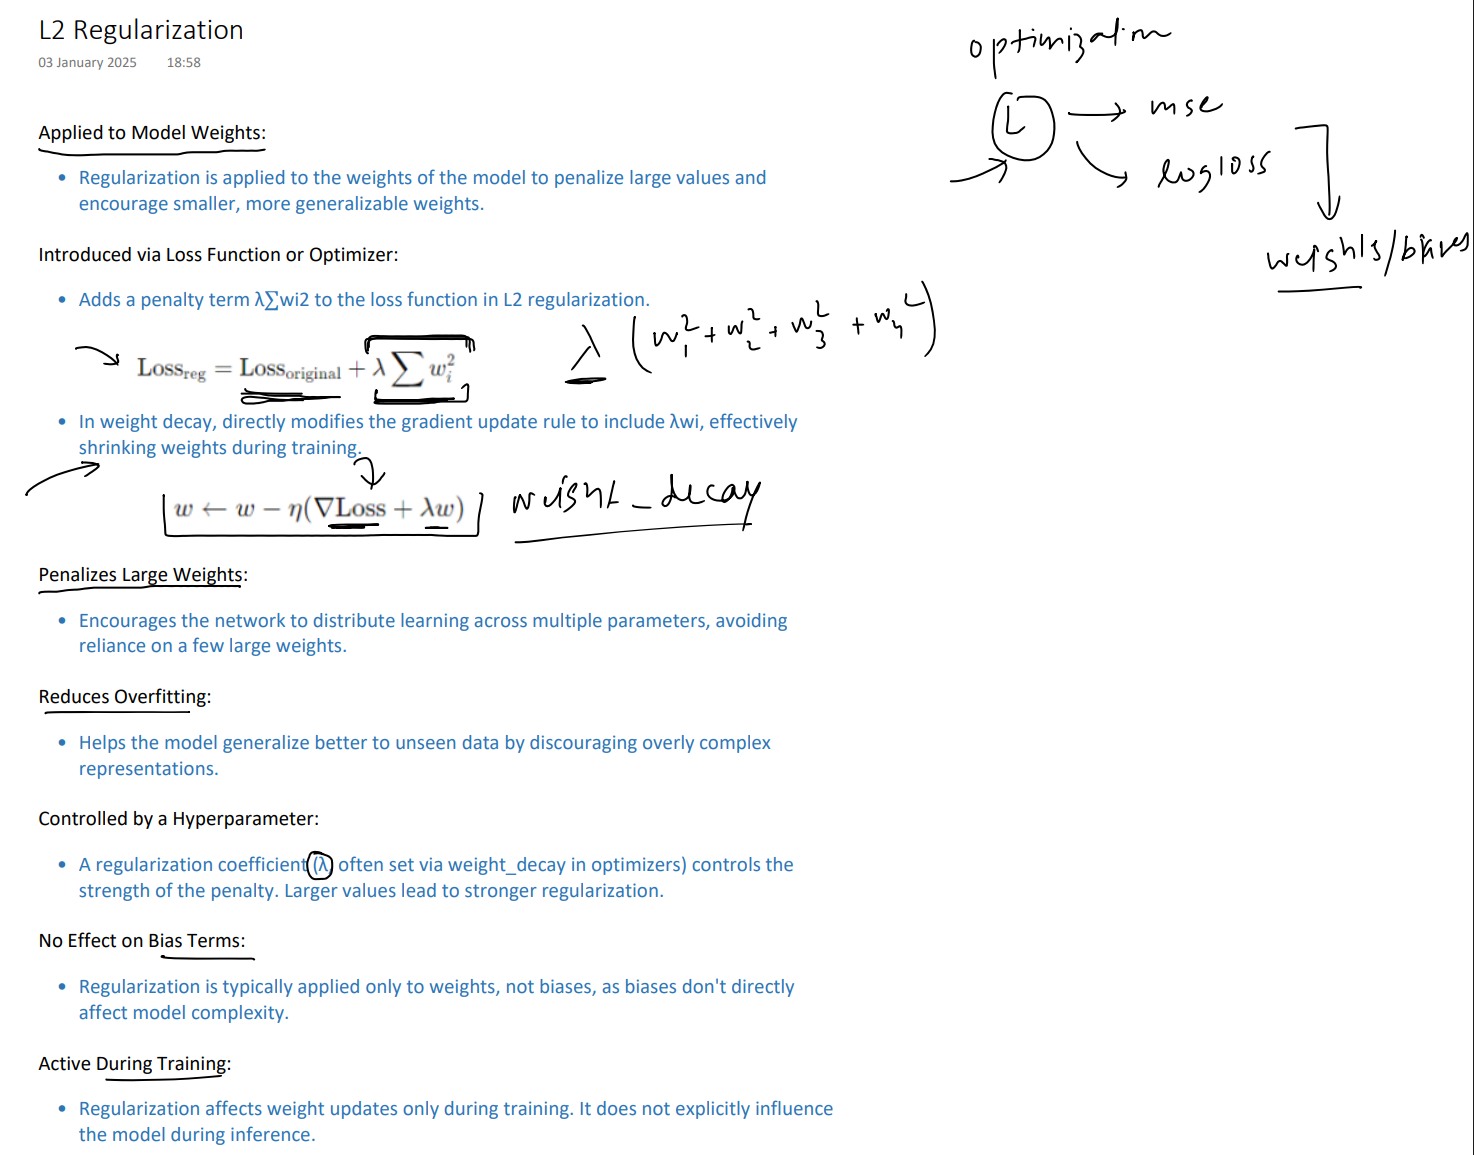

In [42]:
from collections import OrderedDict
import torch.optim as optim

class MyNN(nn.Module):
    def __init__(self, num_features):
        super(MyNN, self).__init__()
        self.model = nn.Sequential(OrderedDict([
            ("input layer", nn.Linear(784, 128)),
            ("BatchNorm1",nn.BatchNorm1d(128)),
            ("ReLU1", nn.ReLU()),
            ("Drop1",nn.Dropout(p=0.3)),
            ("hidden", nn.Linear(128, 64)),
            ( "BatchNorm2",nn.BatchNorm1d(64)),
            ("ReLU2", nn.ReLU()),
            ( "Drop2",nn.Dropout(p=0.3)),
            ("hidden2", nn.Linear(64, 10))
        ]))

    def forward(self, x):
        return self.model(x)

model = MyNN(x_train.shape[1])
model.to(device)
criterion = nn.CrossEntropyLoss()
#applied regularization by adding weight_decay as lembda
optimizer = optim.SGD(model.parameters(), lr=0.01,weight_decay=1e-4)

# 2. Train the corrected model (10 epochs for demonstration)
epochs= 10
print("Training  model...")
for epoch in range(epochs):
    total_epoch_loss = 0
    model.train()
    for batch_features, batch_labels in train_loader:
        #move data to GPU
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

        # Forward pass
        outputs = model(batch_features)
        #loss Calculation
        loss = criterion(outputs, batch_labels)
        # optimizer
        optimizer.zero_grad()
        #bckward pass
        loss.backward()
        #parameters updation
        optimizer.step()

        total_epoch_loss += loss.item()

    avg_epoch_loss = total_epoch_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{epochs}] - Average Loss: {avg_epoch_loss:.4f}")

# 3. Evaluate the corrected model
model.eval()
total = 0
correct = 0

with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
        outputs = model(batch_features)
        _, predicted = torch.max(outputs.data, 1)
        total += batch_labels.size(0)
        correct += (predicted == batch_labels).sum().item()

print(f"Model Test Accuracy: {correct/total:.4f}")

Training  model...
Epoch [1/10] - Average Loss: 0.9498
Epoch [2/10] - Average Loss: 0.6098
Epoch [3/10] - Average Loss: 0.5423
Epoch [4/10] - Average Loss: 0.5088
Epoch [5/10] - Average Loss: 0.4820
Epoch [6/10] - Average Loss: 0.4639
Epoch [7/10] - Average Loss: 0.4444
Epoch [8/10] - Average Loss: 0.4353
Epoch [9/10] - Average Loss: 0.4236
Epoch [10/10] - Average Loss: 0.4129
Model Test Accuracy: 0.8732


In [43]:
model.eval()
total = 0
correct = 0

with torch.no_grad():
    for batch_features, batch_labels in train_loader:
        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)
        outputs = model(batch_features)
        _, predicted = torch.max(outputs.data, 1)
        total += batch_labels.size(0)
        correct += (predicted == batch_labels).sum().item()

print(f"Model Train Accuracy: {correct/total:.4f}")

Model Train Accuracy: 0.8897


In [44]:
# train and test accuracy has improved